# 파일 생성 MCP 서버


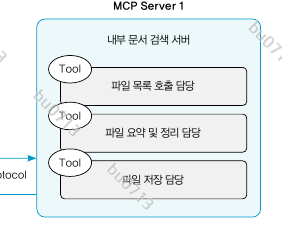

# 세팅

In [1]:
! uv pip install langchain-mcp-adapters

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Audited 1 package in 18ms


In [2]:
import os
from dotenv import load_dotenv

load_dotenv()

if os.environ.get("OPENAI_API_KEY"):
    print("OPENAI API Key가 설정되었습니다.")

OPENAI API Key가 설정되었습니다.


# MCP 서버 구성

In [ ]:
from mcp.server.fastmcp import FastMCP  # FastMCP: MCP 서버를 빠르게 구성하는 클래스 임포트
import os  # 파일 시스템 경로 및 디렉토리 접근용 표준 라이브러리
import stat  # 파일 모드(권한) 문자열 변환용 표준 라이브러리
import time  # 타임스탬프를 사람이 읽는 문자열로 변환하는 표준 라이브러리
from typing import List  # 반환 타입 힌트 List 임포트


mcp = FastMCP(  # [ 1 ] FastMCP 서버 인스턴스 생성
    "FileSearch",  # 서버 이름 지정
    instructions="로컬 파일 검색을 도와주는 어시스턴트입니다."  # 서버 동작 안내 문구 설정
)


# 파일 목록 호출
@mcp.tool()  # [ 2 ] 이 함수를 MCP 도구로 등록
async def file_listup(directory: str) -> List[str]:  # directory 경로를 받아 문자열 리스트 반환
    """지정된 디렉토리 경로의 파일 이름 목록을 반환합니다."""  # 도구 설명(스키마에 노출)
    try:
        return os.listdir(directory)  # 해당 디렉토리 내 항목 이름 리스트 반환
    except Exception as e:  # 접근 실패 등 예외 발생 시
        return [f"오류: {str(e)}"]  # 오류 메시지를 담은 리스트 반환


# 파일 검색 요약 및 정리 담당
@mcp.tool()  # [ 3 ] 이 함수를 MCP 도구로 등록
async def file_info(path: str) -> dict:  # path를 받아 상세 정보 딕셔너리 반환
    """
    지정된 경로의 파일 또는 디렉토리에 대한 상세 정보를 반환합니다.
    """  # 도구 설명(스키마에 노출)
    if not os.path.exists(path):  # 경로가 존재하지 않으면
        return {"error": f"경로 '{path}' 가 존재하지 않습니다."}  # 오류 딕셔너리 반환

    try:
        stat_info = os.stat(path)  # 파일 상태 정보(크기, 시간, 모드 등) 조회

        permissions = stat.filemode(stat_info.st_mode)  # 모드 값을 권한 문자열로 변환

        with open(path, "r", encoding="utf-8") as f:  # 파일을 UTF-8 텍스트 모드로 열기
            content = f.read()  # 파일 전체 내용을 문자열로 읽기

        return {
            "path": os.path.abspath(path),  # 절대 경로
            "content": content,  # 읽어들인 파일 내용
            "type": "file",  # 타입을 "file" 문자열로 지정
            "size": stat_info.st_size,  # bytes  # 파일 크기(바이트)
            "created_time": time.ctime(stat_info.st_birthtime),  # 생성 시각 문자열
            "modified_time": time.ctime(stat_info.st_mtime),  # 수정 시각 문자열
            "access_time": time.ctime(stat_info.st_atime),  # 접근 시각 문자열
            "permissions": permissions,  # 권한 문자열
        }
    except Exception as e:  # 파일 열기/조회 중 예외 발생 시
        return {"error": str(e)}  # 오류 딕셔너리 반환


# 파일 쓰기 저장 담당
@mcp.tool()  # [ 4 ] 이 함수를 MCP 도구로 등록
async def save_file(content: str, output_path="file_info.md") -> str:  # content를 output_path에 저장, 경로 반환
    """제공된 내용을 지정된 output_path의 텍스트 파일에 작성합니다."""  # 도구 설명(스키마에 노출)
    with open(output_path, "w", encoding="utf-8") as f:  # 파일을 UTF-8 쓰기 모드로 열기
        f.write(content)  # content를 파일에 기록

    return output_path  # 저장한 파일 경로 반환


if __name__ == "__main__":  # [ 5 ] 스크립트가 직접 실행될 때만 아래 코드 실행
    # 서버 시작 안내 메시지를 콘솔에 출력
    print("MCP server started and waiting for clients...")
    # streamable-http 전송 방식으로 MCP 서버를 실행 (기본적으로 http://localhost:8000/mcp 에서 대기)
    mcp.run(transport="streamable-http")

서버 커기

 uv run fileserver.py 

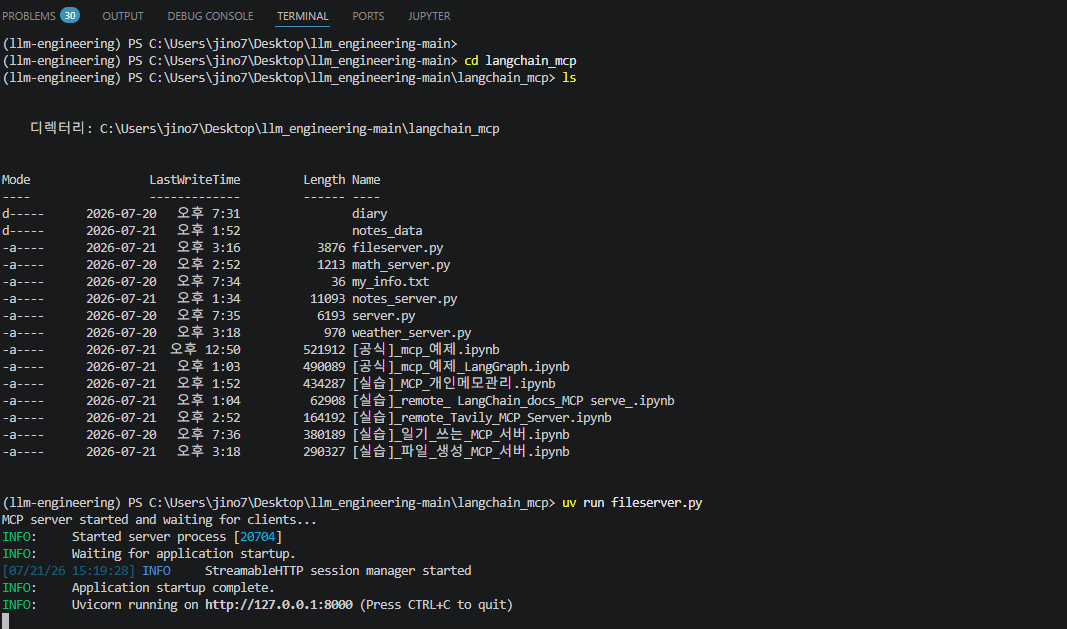

# MCP 클라이언트 구성

In [9]:
# ============================================
# [셀 1] 임포트 및 기본 설정
# ============================================
import gradio as gr
from langchain_mcp_adapters.client import MultiServerMCPClient
from langchain_mcp_adapters.prompts import load_mcp_prompt
from langchain.agents import create_agent
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import InMemorySaver
from dotenv import load_dotenv

# 에이전트의 시스템 프롬프트(역할·행동 지침) 문자열
# create_agent에 str로 전달되면 내부에서 SystemMessage로 변환되어
# 매 모델 호출 시 메시지 목록 맨 앞에 추가됨
SYSTEM_PROMPT = (
    "당신은 파일 관리 전문 AI 비서입니다. "
    "사용자의 파일을 생성, 조회, 검색, 수정, 삭제하는 작업을 도와줍니다."
    "사용자로부터 파일의 내용을 중심으로 입력받고, 제목이나 태그가 명시되지 않았다면 자동으로 생성하여 저장하세요."
)

# 사용할 LLM 모델 정의
model = ChatOpenAI(model="gpt-5-mini")

# "FileSearch" MCP 서버에 streamable_http 전송 방식으로 연결하는 클라이언트를 생성
# 서버(server.py)는 포트 8000에서 mcp.run(transport="streamable-http")로 실행 중이어야 함
client = MultiServerMCPClient(
    {
        "FileSearch": {
            "url": "http://localhost:8000/mcp",
            "transport": "streamable_http",
        },
    }
)

# 대화 기록을 저장하는 체크포인터
# 매 요청마다 에이전트를 새로 만들더라도, 같은 thread_id로 조회하면
# 이전 대화 내용이 그대로 이어짐
checkpointer = InMemorySaver()

In [10]:
# ============================================
# [셀 2] Gradio에서 호출할 비동기 응답 함수
# ============================================
async def respond(message, history):
    """
    Gradio ChatInterface가 호출하는 응답 함수.
    message: 사용자가 방금 입력한 텍스트
    history: 지금까지의 화면상 대화 기록 (list)
    """
    # MCP 서버의 tool들을 LangChain tool 형태로 변환
    tools = await client.get_tools()

    # system_prompt로 역할 지침을 전달하여 에이전트 생성
    # 전달한 문자열은 내부에서 SystemMessage로 변환되어 메시지 맨 앞에 추가됨
    agent = create_agent(
        model,
        tools,
        system_prompt=SYSTEM_PROMPT,
        checkpointer=checkpointer,
    )

    # 역할 지침은 system_prompt가 담당하므로 매 턴 사용자 메시지만 전달
    # 이전 대화는 checkpointer가 thread_id 기준으로 복원
    response = await agent.ainvoke(
        {"messages": [{"role": "user", "content": message}]},
        config={"configurable": {"user_id": "user_123", "thread_id": "1"}},
    )

    # 마지막 메시지(최종 AI 응답)의 내용을 반환
    return response["messages"][-1].content

현재 폴더 파일 검색

test.md 빈파일 생성해줘

In [11]:
# ============================================
# [셀 3] Gradio UI 실행
# ============================================
demo = gr.ChatInterface(
    fn=respond,                # 비동기 함수도 그대로 전달 가능
    type="messages",           # OpenAI 스타일 messages 형식 사용
    title="MCP 파일 서버",
    description="파일을 검색하고 생성할 수 있습니다.",
)

# 주피터 노트북에서는 launch() 호출 시 셀 출력 영역에 UI가 인라인으로 표시됨
demo.launch()

* Running on local URL:  http://127.0.0.1:7865
* To create a public link, set `share=True` in `launch()`.


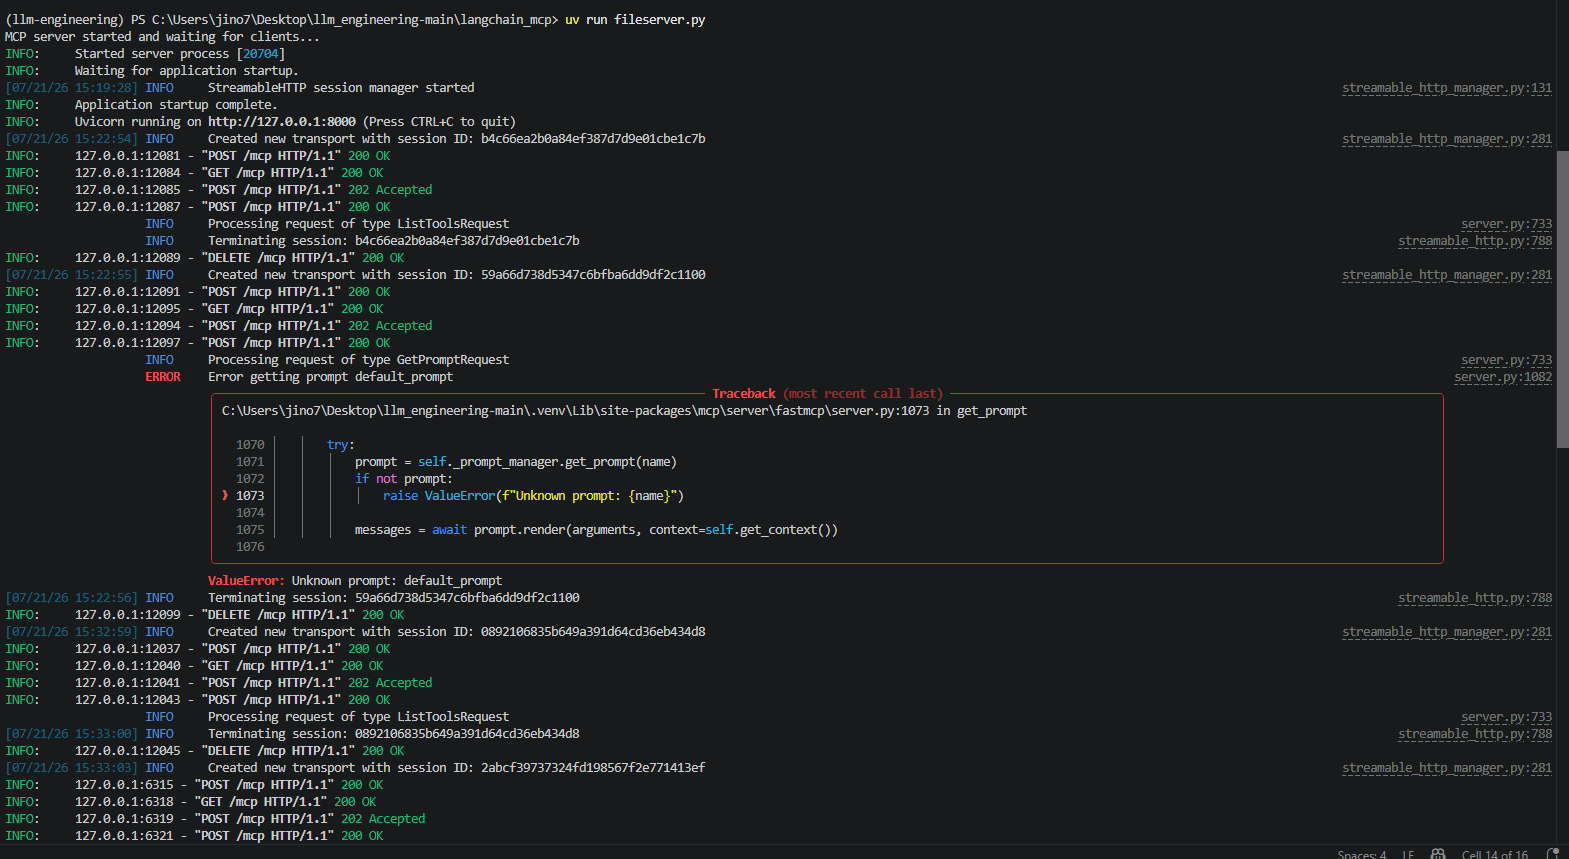